# 02 — Featurization

Build the modeling dataset, inspect the feature matrix, and explore
feature groups before running full experiments.

In [15]:
# Automatic module reloading
%load_ext autoreload
%autoreload 2

import sys
from pathlib import Path

ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT))

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from src.modeling.config import load_dataset_config
from src.modeling.dataset import build_modeling_dataset
from src.modeling.features import (
    merge_external_features,
    build_feature_pipeline,
    featurize,
    get_feature_names,
    build_feature_group_index,
)

sns.set_theme(style="whitegrid")

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


## 1. Load config and build modeling dataset

In [16]:
cfg = load_dataset_config(ROOT / "config/dataset/modeling_dataset_aero_anaero.yaml")

In [17]:
df = build_modeling_dataset(cfg, root=ROOT)
df.head()

2026-07-03 18:02:59.218 | INFO     | src.modeling.dataset:build_modeling_dataset:72 - loading curves: [PosixPath('/scratch/chinasse/MicrobeNet/data/processed/aerobic_tidy_curves.csv'), PosixPath('/scratch/chinasse/MicrobeNet/data/processed/anaerobic_tidy_curves.csv')]
2026-07-03 18:02:59.230 | INFO     | src.modeling.dataset:_load_curves:41 - loaded 2 curves files, total shape: 1260 rows x 17 cols
2026-07-03 18:02:59.233 | INFO     | src.modeling.dataset:build_modeling_dataset:77 - removed water controls, shape: 1155 rows x 17 cols
2026-07-03 18:02:59.234 | INFO     | src.modeling.dataset:build_modeling_dataset:81 - removed `other` strains, shape: 1111 rows x 17 cols
2026-07-03 18:02:59.236 | INFO     | src.modeling.dataset:build_modeling_dataset:85 - removed `empty` strains, shape: 1078 rows x 17 cols
2026-07-03 18:02:59.236 | INFO     | src.modeling.dataset:build_modeling_dataset:90 - loading strain metadata: /scratch/chinasse/MicrobeNet/data/external/strains_metadata.csv
2026-07-03 

,exp_id,date,well_id,row,col,well_index,strain_name,media_name,atmosphere,temperature,...,ncbi_taxon_id,assembly_level,genome_size_bp,gc_content_pct,num_contigs,n50,sequence_hash,date_retrieved,resolution_method,requires_verification
0,aerobic_a_25,20260325,a_1_0,a,1,0,escherichia coli k12,lb,aerobic,25.0,...,562,scaffold,4685496,50.7,63,149239,9a7a1ab441a951df4b1e30be071faaee595fd48de0f8e7...,2026-06-24,NCBI assembly search by ATCC number,no
1,aerobic_a_25,20260325,a_2_1,a,2,1,escherichia coli k12,mb,aerobic,25.0,...,562,scaffold,4685496,50.7,63,149239,9a7a1ab441a951df4b1e30be071faaee595fd48de0f8e7...,2026-06-24,NCBI assembly search by ATCC number,no
2,aerobic_a_25,20260325,a_3_2,a,3,2,escherichia coli k12,nb,aerobic,25.0,...,562,scaffold,4685496,50.7,63,149239,9a7a1ab441a951df4b1e30be071faaee595fd48de0f8e7...,2026-06-24,NCBI assembly search by ATCC number,no
3,aerobic_a_25,20260325,a_4_3,a,4,3,escherichia coli k12,bhi,aerobic,25.0,...,562,scaffold,4685496,50.7,63,149239,9a7a1ab441a951df4b1e30be071faaee595fd48de0f8e7...,2026-06-24,NCBI assembly search by ATCC number,no
4,aerobic_a_25,20260325,a_5_4,a,5,4,escherichia coli k12,mrs,aerobic,25.0,...,562,scaffold,4685496,50.7,63,149239,9a7a1ab441a951df4b1e30be071faaee595fd48de0f8e7...,2026-06-24,NCBI assembly search by ATCC number,no


In [18]:
print(f"Shape: {df.shape}")
print(f"Strains: {df['strain_name'].nunique()}")
print(f"Strains: {df['strain_name'].unique()}")
print(f"Media: {df['media_name'].nunique()}")
print(f"Media: {df['media_name'].unique()}")
print(f"Growth class distribution:\n{df['growth_class'].value_counts()}")

Shape: (1078, 30)
Strains: 25
Strains: <ArrowStringArray>
[         'escherichia coli k12',    'corynebacterium glutamicum',
            'pseudomonas putida',             'bacillus subtilis',
         'escherichia coli bl21',    'streptococcus thermophilus',
      'bifidobacterium animalis',          'acinetobacter baylyi',
           'priestia megaterium',         'gluconobacter oxydans',
      'acetobacter pasteurianus',           'cupriavidus necator',
      'arthrobacter globiformis',      'paracoccus denitrificans',
       'deinococcus radiodurans',            'kocuria rhizophila',
            'micrococcus luteus',             'acetobacter aceti',
        'azotobacter vinelandii',        'caulobacter vibrioides',
     'lactobacillus acidophilus', 'lactiplantibacillus plantarum',
      'pediococcus acidilactici',        'clostridium sporogenes',
      'komagataeibacter xylinus']
Length: 25, dtype: str
Media: 11
Media: <ArrowStringArray>
['lb', 'mb', 'nb', 'bhi', 'mrs', 'thy', 'tsb'

## 2. Build and inspect feature pipeline

In [19]:
# Build (unfitted) transformer
df = merge_external_features(cfg, df, root=ROOT)
ct, feature_cols, fgm = build_feature_pipeline(cfg, df, root=ROOT)
print(f"Raw feature columns: {feature_cols}")
print(f"Feature group map: {fgm}")

2026-07-03 18:02:59.317 | INFO     | src.modeling.features:merge_external_features:152 - merging external features from /scratch/chinasse/MicrobeNet/data/metadata/modeling/media_features.csv on key 'media_name'


2026-07-03 18:02:59.325 | INFO     | src.modeling.features:build_feature_pipeline:219 - loading feature table from /scratch/chinasse/MicrobeNet/data/metadata/modeling/media_features.csv


Raw feature columns: ['genome_size_bp', 'gc_content_pct', 'num_contigs', 'n50', 'has_blood_components', 'has_yeast_extract', 'has_peptone', 'complexity', 'richness', 'atmosphere', 'temperature']
Feature group map: {'genome_size_bp': 'strain', 'gc_content_pct': 'strain', 'num_contigs': 'strain', 'n50': 'strain', 'complexity': 'media_emb', 'richness': 'media_emb', 'has_blood_components': 'media_emb', 'has_yeast_extract': 'media_emb', 'has_peptone': 'media_emb', 'atmosphere': 'condition', 'temperature': 'condition'}


In [20]:
# Fit on all data (EDA only — NOT for CV reporting)
ct.fit(df)
X = ct.transform(df)
feature_names = get_feature_names(ct)

print(f"X shape: {X.shape}")
print(f"Feature names ({len(feature_names)}): {feature_names}")

X shape: (1078, 16)
Feature names (16): ['genome_size_bp', 'gc_content_pct', 'num_contigs', 'n50', 'has_blood_components', 'has_yeast_extract', 'has_peptone', 'complexity_defined', 'complexity_semi_defined', 'complexity_undefined', 'richness_minimal', 'richness_moderate', 'richness_rich', 'atmosphere_aerobic', 'atmosphere_anaerobic', 'temperature']


In [21]:
# Feature group index (for SHAP grouping)
group_idx = build_feature_group_index(feature_names, fgm)
for group, indices in group_idx.items():
    print(f"{group}: {len(indices)} features (indices {indices[:5]}...)")

strain: 4 features (indices [0, 1, 2, 3]...)
media_emb: 9 features (indices [4, 5, 6, 7, 8]...)
condition: 3 features (indices [13, 14, 15]...)


## 3. Wrapper for notebook exploration

In [22]:
X, y, feat_names, groups, fgm = featurize(df, cfg, target="growth_class", root=ROOT)
print(f"X: {X.shape}, y: {y.shape}, unique groups: {len(np.unique(groups))}")

2026-07-03 18:02:59.437 | INFO     | src.modeling.features:merge_external_features:152 - merging external features from /scratch/chinasse/MicrobeNet/data/metadata/modeling/media_features.csv on key 'media_name'
2026-07-03 18:02:59.440 | DEBUG    | src.modeling.features:merge_external_features:159 - columns ['complexity', 'richness', 'has_blood_components', 'has_yeast_extract', 'has_peptone'] already in DataFrame — skipping merge
2026-07-03 18:02:59.441 | INFO     | src.modeling.features:build_feature_pipeline:219 - loading feature table from /scratch/chinasse/MicrobeNet/data/metadata/modeling/media_features.csv


X: (1078, 16), y: (1078,), unique groups: 25


## 4. Visualize feature matrix

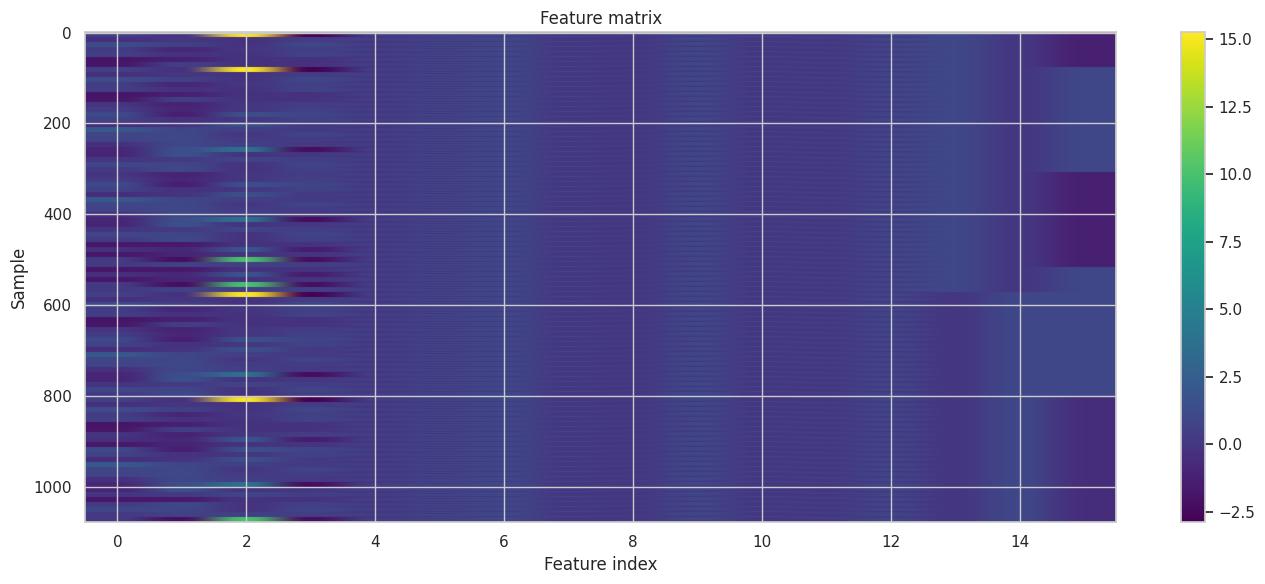

In [23]:
fig, ax = plt.subplots(figsize=(14, 6))
im = ax.imshow(X[:], aspect="auto", cmap="viridis")
ax.set_xlabel("Feature index")
ax.set_ylabel("Sample")
ax.set_title("Feature matrix")
plt.colorbar(im, ax=ax)
plt.tight_layout()
plt.show()